In [2]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd 
import numpy as np 
import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt
from pathlib import Path

In [3]:
import matplotlib.pyplot as plt

## EW vs CW: Historical Performance

### Let us first pull up the data for industries.

In [4]:
dt.update_all_data()

In [5]:
rets_cw = dt.get_ind_returns(n_inds=30, weighting='vw')
rets_ew = dt.get_ind_returns(n_inds=30, weighting='ew')

### Now we constructed a DF for industries returns under differnet weighting schemes: Cap-Weighted vs Equal Weights

In [6]:
ann_rets = pd.DataFrame({
    "CW industries": pt.annualize_rets(rets_cw, 12),
    "EW industries": pt.annualize_rets(rets_ew, 12)
})
ann_rets.head()

,CW industries,EW industries
Food,0.103985,0.113141
Beer,0.112479,0.113665
Smoke,0.126356,0.125925
Games,0.089118,0.088839
Books,0.078834,0.112101


<Axes: >

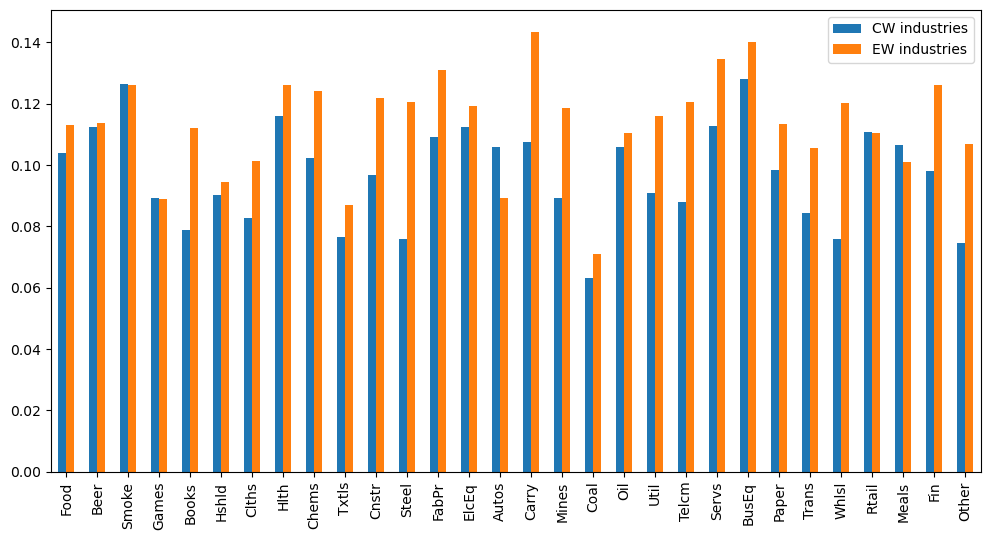

In [7]:
ann_rets.plot.bar(figsize = (12,6))

In [8]:
diff = (ann_rets['EW industries'] - ann_rets['CW industries'])
cond = diff > 0 
n = int(cond.sum() / len(diff)*100)

In [9]:
n , (diff * cond).sum() / cond.sum() , diff.max()

(83, np.float64(0.02068609801307515), 0.04469089692042938)

In [10]:
round(diff*100,2)

Food     0.92
Beer     0.12
Smoke   -0.04
Games   -0.03
Books    3.33
Hshld    0.41
Clths    1.85
Hlth     1.00
Chems    2.20
Txtls    1.04
Cnstr    2.51
Steel    4.47
FabPr    2.18
ElcEq    0.69
Autos   -1.66
Carry    3.58
Mines    2.92
Coal     0.78
Oil      0.45
Util     2.52
Telcm    3.27
Servs    2.18
BusEq    1.22
Paper    1.50
Trans    2.13
Whlsl    4.43
Rtail   -0.06
Meals   -0.53
Fin      2.81
Other    3.23
dtype: float64

### What is clearly seen, in an absolute majority of 26 industries out of 30 EW overtook CW by 2% on average on annualised terms.
However, I tried to change the period and shorten the window of observation and the distinction became less obvious, let's see together.
For that purpose I will use the same Data of 30 inds.

In [11]:
roll_60_cw = rets_cw.rolling(60).apply(lambda x: pt.annualize_rets(x, periods_per_year = 12))
roll_60_ew = rets_ew.rolling(60).apply(lambda x: pt.annualize_rets(x, periods_per_year = 12))

In [12]:
ew_sub_cw = roll_60_ew.sub(roll_60_cw)
mean_cw = roll_60_cw.mean(axis = 'columns')
mean_ew = roll_60_ew.mean(axis = 'columns')

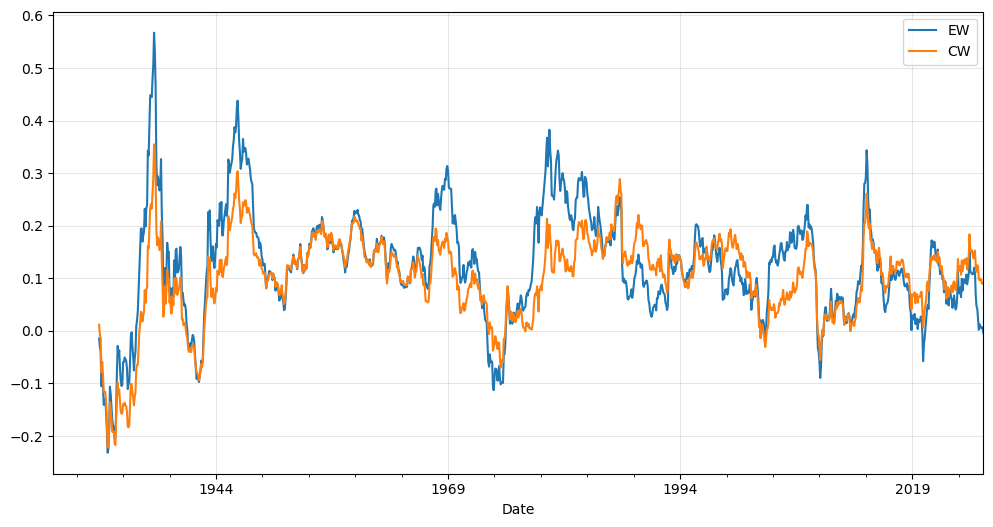

In [13]:
df = pd.concat([mean_ew, mean_cw], axis=1)
df.columns = ["EW", "CW"]
ax = df.plot(figsize = (12,6))
ax.grid(True, c = 'black', alpha = 0.1)

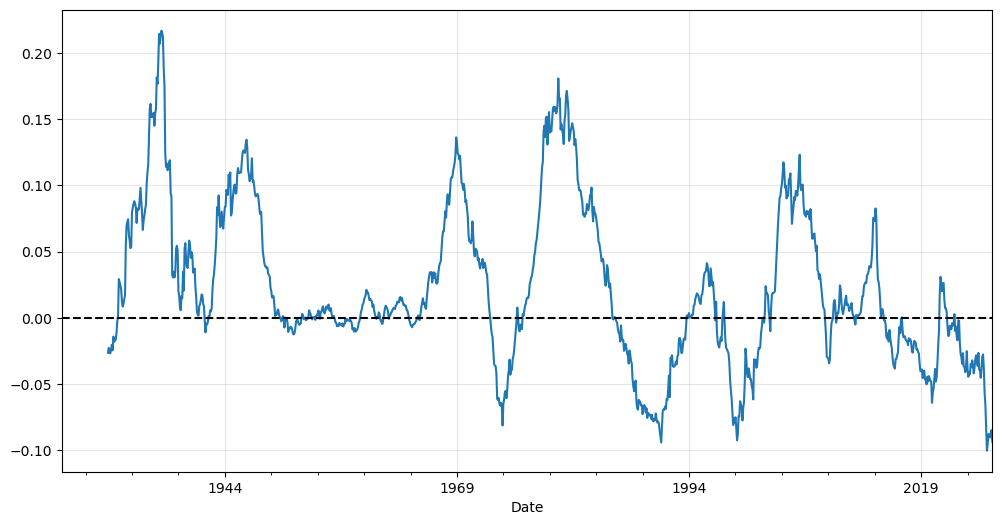

In [14]:
ax = ew_sub_cw.mean(axis=1).plot(figsize=(12,6))
plt.axhline(0, color="black", linestyle="--")
ax.grid(True, c = 'black', alpha = 0.1)

### What is this graph ?
So the graph shows the average 5-year annualized EW–CW return spread across industries. Positive values mean EW outperformed CW on average; negative values mean CW outperformed.

It looks like there is a trend towards the (EW-CW) spread turning negative. As we see, it was a much more obvious advantage to hold EW portfolio for selected industries in the first third of the period considered.  

```
Lets look at it from a different perspectiv: we will consider other grouping options as well, that is, 49, 12 and 10 industries (which are as well publicly available).

In [15]:

data = pd.DataFrame(index = roll_60_cw.index)

for n in [10,12,30,49]:
    roll_ew = dt.get_ind_returns(n_inds=n, weighting='ew').rolling(60).apply(lambda x: pt.annualize_rets(x, periods_per_year = 12))
    roll_cw = dt.get_ind_returns(n_inds=n, weighting='vw').rolling(60).apply(lambda x: pt.annualize_rets(x, periods_per_year = 12))

    diff = (roll_ew.sub(roll_cw)).mean(axis = 'columns')

    data[f'{n} inds'] = diff
    
data 

,10 inds,12 inds,30 inds,49 inds
Date,,,,
1926-07,NaN,NaN,NaN,NaN
1926-08,NaN,NaN,NaN,NaN
1926-09,NaN,NaN,NaN,NaN
1926-10,NaN,NaN,NaN,NaN
1926-11,NaN,NaN,NaN,NaN
...,...,...,...,...
2026-05,-0.101898,-0.092000,-0.089950,-0.081597
2026-06,-0.099154,-0.090844,-0.090064,-0.082077
2026-07,-0.095425,-0.087630,-0.086128,-0.080827


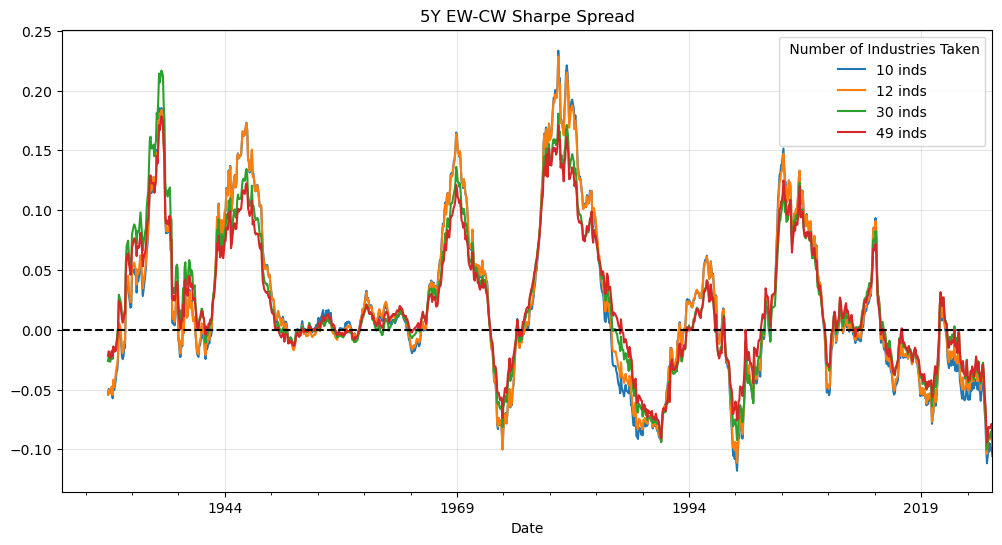

In [16]:
ax = data.plot(figsize = (12,6), title =  '5Y EW-CW Sharpe Spread')
ax.legend(title=" Number of Industries Taken")
plt.axhline(0, color="black", linestyle="--")
ax.grid(True, c = 'black', alpha = 0.1)

That suggests the time variation in the EW–CW return spread is not mainly an artifact of choosing 30 industries.

### Let us now look at it from risk-adjusted perspective - we will use trailing 5Y Sharpe Ratio Comparison.

In [17]:
rf = dt.get_fff_returns()['RF']
rf.head()

Date
1926-07    0.0022
1926-08    0.0025
1926-09    0.0023
1926-10    0.0032
1926-11    0.0031
Freq: M, Name: RF, dtype: float64

In [18]:
sr_cw = rets_cw.rolling(60).apply(pt.sharpe_ratio, kwargs = {'riskfree_rate': rf, 'periods_per_year':12})
sr_ew = rets_ew.rolling(60).apply(pt.sharpe_ratio, kwargs = {'riskfree_rate': rf, 'periods_per_year':12})

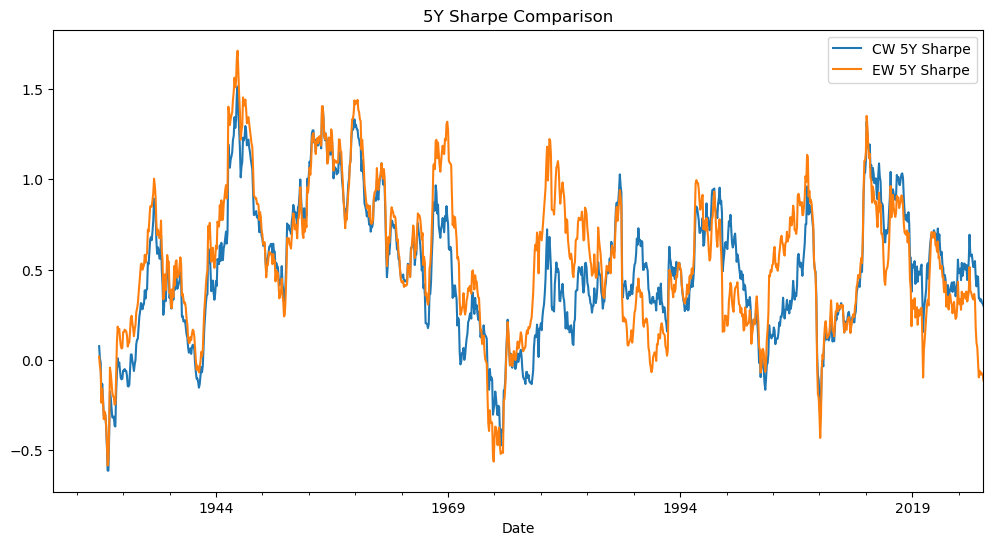

In [19]:
ax = sr_cw.mean(axis = 1).plot(title = '5Y Sharpe Comparison', figsize = (12,6), label = "CW 5Y Sharpe")
sr_ew.mean(axis = 1).plot(ax=ax, label = "EW 5Y Sharpe" )
ax.legend()

Let's just look at the spread:

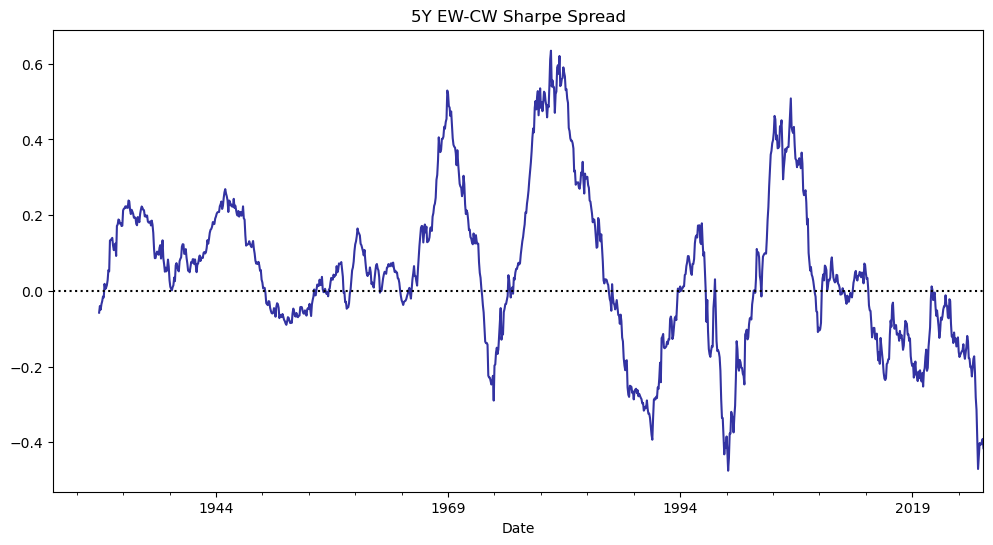

In [20]:
sr_spread = sr_ew.sub(sr_cw).mean(axis = 'columns')
sr_spread.plot(title = '5Y EW-CW Sharpe Spread', figsize = (12,6), c = 'darkblue', alpha = 0.8)
plt.axhline(y = 0, color = 'black', ls= ':')

We can see the same pattern - negative trend. 

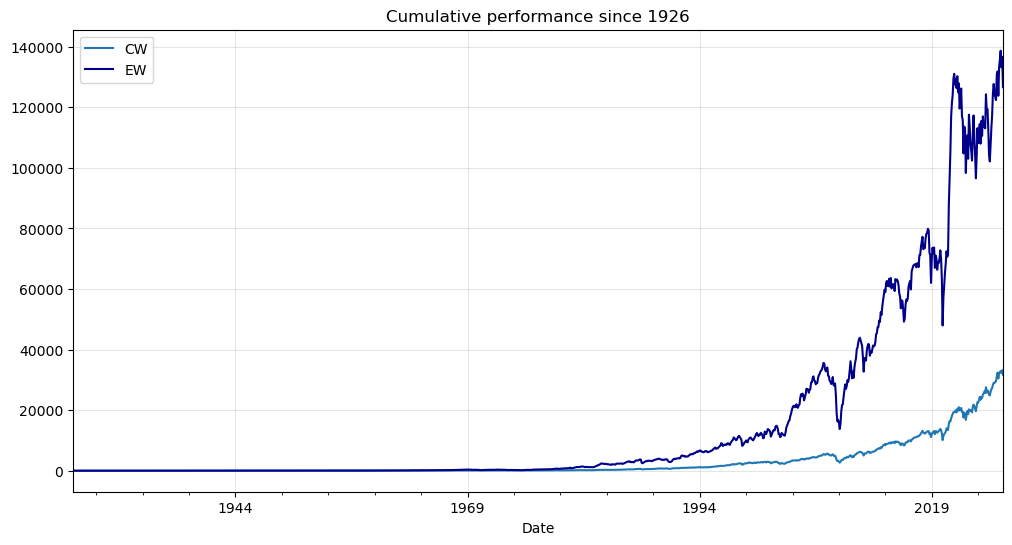

In [21]:
ax = (rets_cw.mean(axis = 'columns')+1).cumprod().plot(figsize = (12,6), label = 'CW', title = 'Cumulative performance since 1926')
(rets_ew.mean(axis = 'columns')+1).cumprod().plot(ax=ax, label = 'EW', c = 'darkblue')
ax.legend()
ax.grid(True, c = 'black', alpha = 0.1)

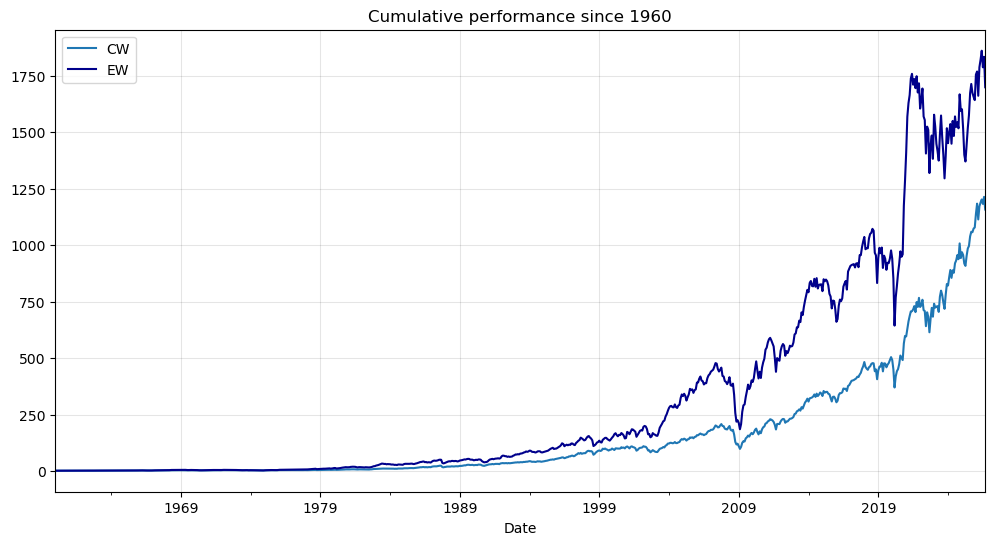

In [22]:
ax = (rets_cw["1960":].mean(axis = 'columns')+1).cumprod().plot(figsize = (12,6), label = 'CW',title = 'Cumulative performance since 1960')
(rets_ew["1960":].mean(axis = 'columns')+1).cumprod().plot(ax=ax, label = 'EW', c = 'darkblue')
ax.legend()
ax.grid(True, c = 'black', alpha = 0.1)

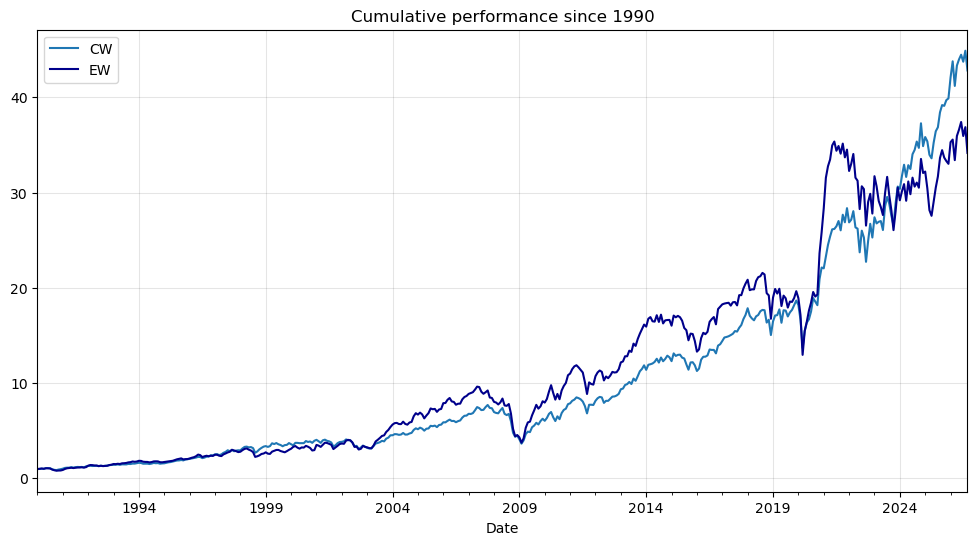

In [23]:
ax = (rets_cw["1990":].mean(axis = 'columns')+1).cumprod().plot(figsize = (12,6), label = 'CW',title = 'Cumulative performance since 1990')
(rets_ew["1990":].mean(axis = 'columns')+1).cumprod().plot(ax=ax, label = 'EW', c = 'darkblue')
ax.legend()
ax.grid(True, c = 'black', alpha = 0.1)

### Preliminary cross-industry comparison
At this stage, these series are simple cross-sectional averages of industry portfolio returns rather than formally constructed aggregate indices. A more appropriate portfolio construction is introduced below.
Yet, we can notice interesting results and draw some conclusions.

***The EW advantage is clearly time-varying. Five-year rolling return and Sharpe spreads frequently change sign, showing that EW does not consistently dominate CW across all periods. The recent sample is particularly weaker for EW on a risk-adjusted basis.
The pattern is also similar across the 10-, 12-, 30-, and 49-industry classifications, suggesting that the result is not driven by the chosen industry granularity.***


### Now we construct proper indecies (taking 49 industries) for a better comparison
To be concrete, if we change stock weighting inside every industry from value weighting to equal weighting, what happens once those industries are aggregated according to their economic size?
So, we compare aggregate indecies for two weighting schemes inside each industry.
in the end, it is just another way to compare two weighting schemes on aggreagted scale. 

In [24]:
idx_rets_cw = dt.get_total_market_index_rets(n_inds=49, weighting='vw')["1960":]
idx_rets_cw.isna().mean(axis = 0).sum()

np.float64(0.0)

In [25]:
idx_rets_ew = dt.get_total_market_index_rets(n_inds=49, weighting='ew')["1960":]

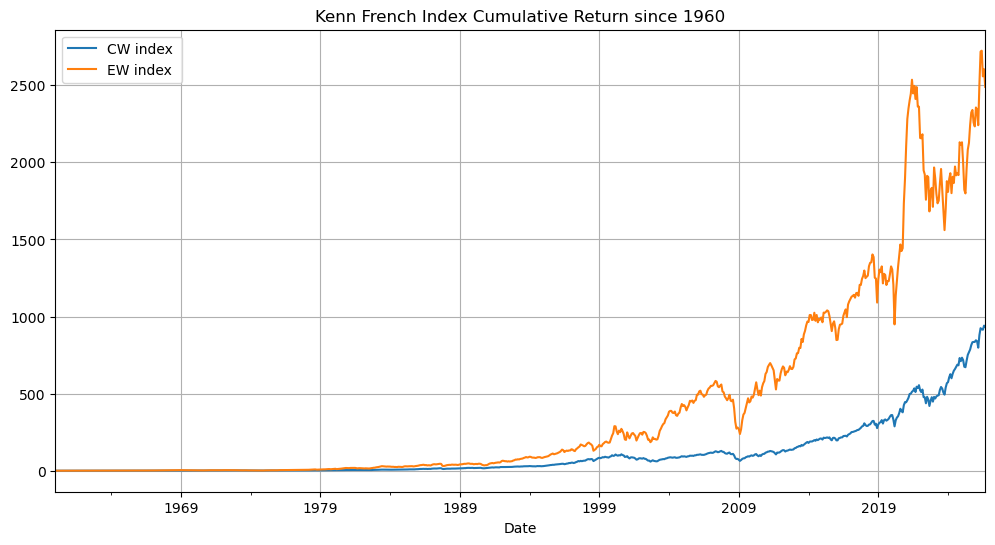

In [26]:
btr = pd.DataFrame({
    "CW index ": idx_rets_cw,
    "EW index ": idx_rets_ew
})
ax = (btr+1).cumprod().plot(figsize = (12,6), grid = True, title = 'Kenn French Index Cumulative Return since 1960')

In [27]:
pt.summary_stats(btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
CW index,0.107891,0.152606,-0.464732,4.671825,0.067017,0.094048,0.557162,-0.500086
EW index,0.124281,0.199451,-0.172745,5.316795,0.083278,0.117442,0.541752,-0.590369


Using the 49-industry aggregation, the EW-based index delivered a substantially higher annualized return: 12.5% vs 10.8% for CW.

However, this came with materially higher risk: EW volatility was about 19.9% vs 15.3%, with a deeper maximum drawdown (-59% vs -50%) and higher tail risk. This trade-off is reflected in similar Sharpe Ratio Values. 

### Lets look at the difference for other timeframes:

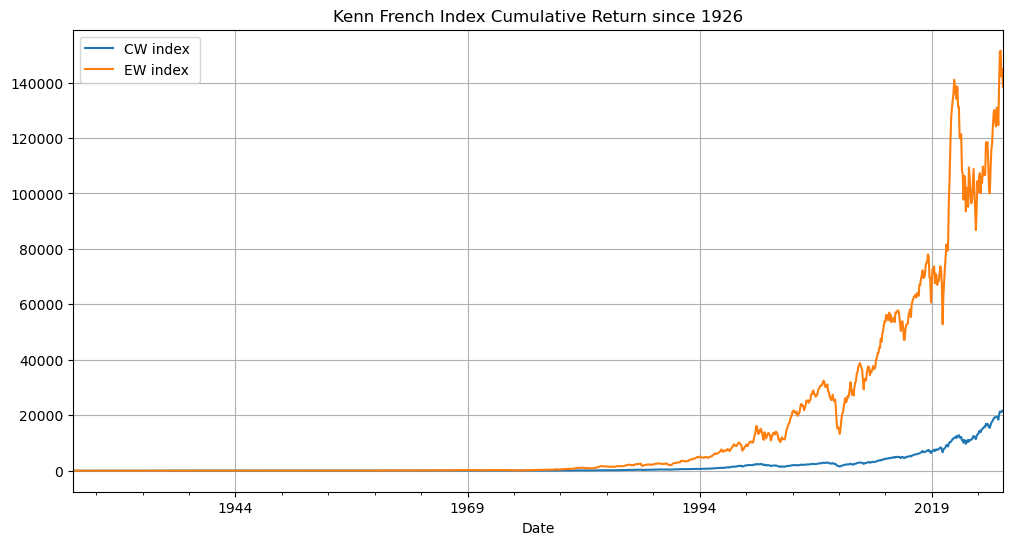

In [28]:
idx_rets_cw_26 = dt.get_total_market_index_rets(n_inds=49, weighting='vw')["1926":]
idx_rets_ew_26= dt.get_total_market_index_rets(n_inds=49, weighting='ew')["1926":]
idx_rets_cw_90 = dt.get_total_market_index_rets(n_inds=49, weighting='vw')["1990":]
idx_rets_ew_90= dt.get_total_market_index_rets(n_inds=49, weighting='ew')["1990":]

btr_26 = pd.DataFrame({
    "CW index ": idx_rets_cw_26,
    "EW index ": idx_rets_ew_26
})
btr_90 = pd.DataFrame({
    "CW index ": idx_rets_cw_90,
    "EW index ": idx_rets_ew_90
})
ax = (btr_26+1).cumprod().plot(figsize = (12,6), grid = True, title = 'Kenn French Index Cumulative Return since 1926')

In [29]:
pt.summary_stats(btr_26)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
CW index,0.104654,0.182667,0.136675,10.448598,0.066994,0.116016,0.476239,-0.833751
EW index,0.125339,0.237767,0.855040,12.621964,0.069733,0.141525,0.490184,-0.848710


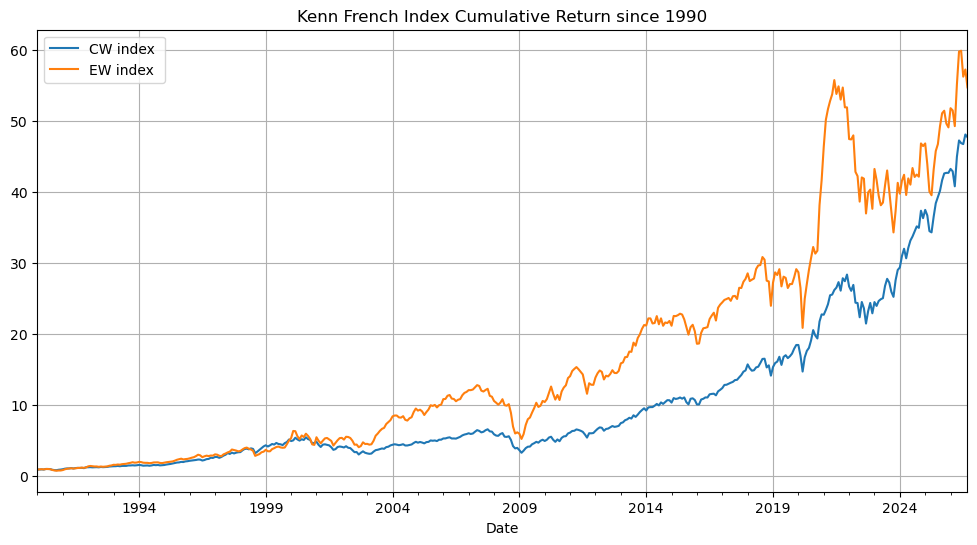

In [30]:
ax = (btr_90+1).cumprod().plot(figsize = (12,6), grid = True, title = 'Kenn French Index Cumulative Return since 1990')

In [31]:
pt.summary_stats(btr_90)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
CW index,0.110890,0.150709,-0.549442,4.054448,0.067341,0.095000,0.580362,-0.500086
EW index,0.115043,0.204141,-0.082411,4.845054,0.085153,0.121304,0.492708,-0.590369


### We see the same pattern as we come closer to the current period: EW scheme performs worse on Risk Adjusted basis. 

## CRSP Equal-Weighted vs Value-Weighted Market Index

Before moving to the stock-level portfolio experiment, I briefly compare the CRSP equal-weighted and value-weighted market indices downloaded from WRDS. The purpose is to check whether the broad U.S. equity market exhibits a similar EW–VW performance pattern to the one observed earlier in the Kenneth French industry portfolios.

In [32]:
processed_dir = Path("../data/processed")
data_crsp = pd.read_csv(processed_dir/"CRSPvw_ew_SP500.csv", index_col =0).iloc[:,[0,1,2,3]]

In [33]:
data_crsp

,vwretd,vwretx,ewretd,ewretx
mthcaldt,,,,
1926-01-30,0.000561,-0.001395,0.023174,0.021395
1926-02-27,-0.033046,-0.036587,-0.053510,-0.055547
1926-03-31,-0.064002,-0.070021,-0.096824,-0.101404
1926-04-30,0.037029,0.034043,0.032975,0.030156
1926-05-28,0.012095,0.008585,0.001035,-0.001752
...,...,...,...,...
2025-08-29,0.024123,0.022883,0.043338,0.041347
2025-09-30,0.035626,0.034162,0.036921,0.034252
2025-10-31,0.019284,0.018508,0.004205,0.002371


### CRSP return series

- **`vwretd`** — value-weighted market return **including dividends/distributions**.
- **`vwretx`** — value-weighted market return **excluding dividends/distributions**.
- **`ewretd`** — equal-weighted market return **including dividends/distributions**.
- **`ewretx`** — equal-weighted market return **excluding dividends/distributions**.

Since the analysis focuses on total investor returns, I primarily use `vwretd` and `ewretd`.

In [34]:
ds_cum = {}
for start in ["1926", "1960", "1990", "2010"]:
    ds_cum[start] = (data_crsp.loc[start:,["vwretd","ewretd"]]+1).cumprod()
    ds_cum[start].columns = ["CW", "EW"]

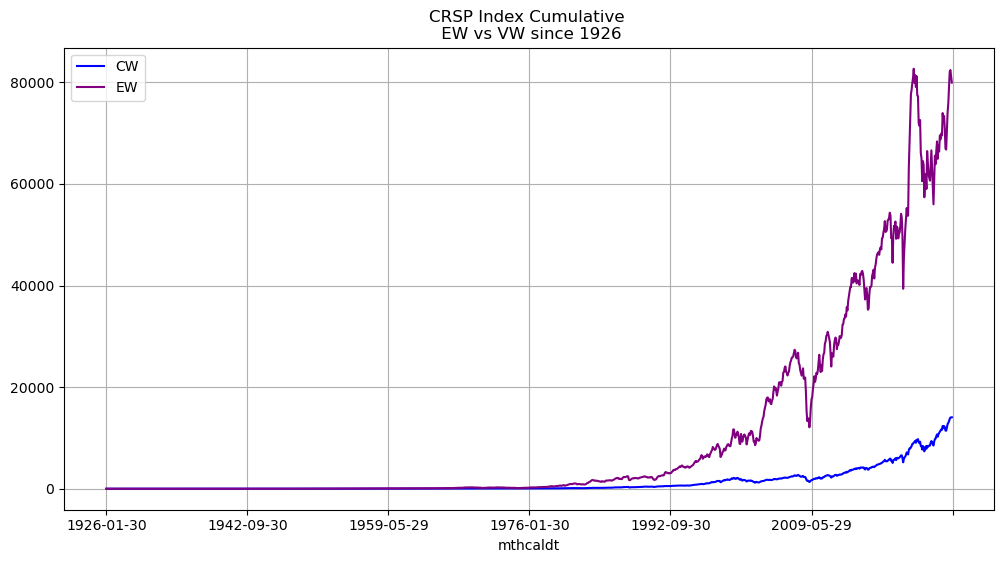

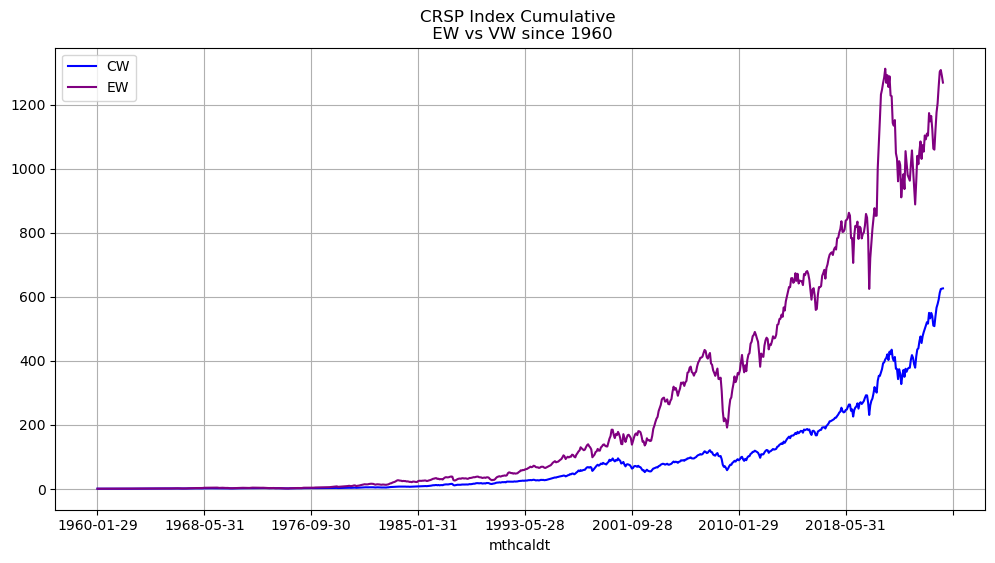

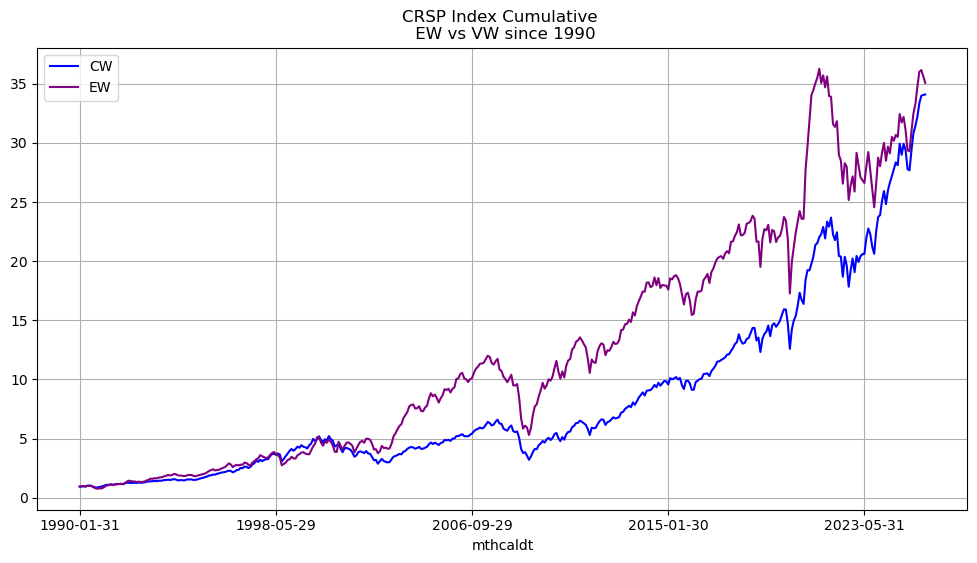

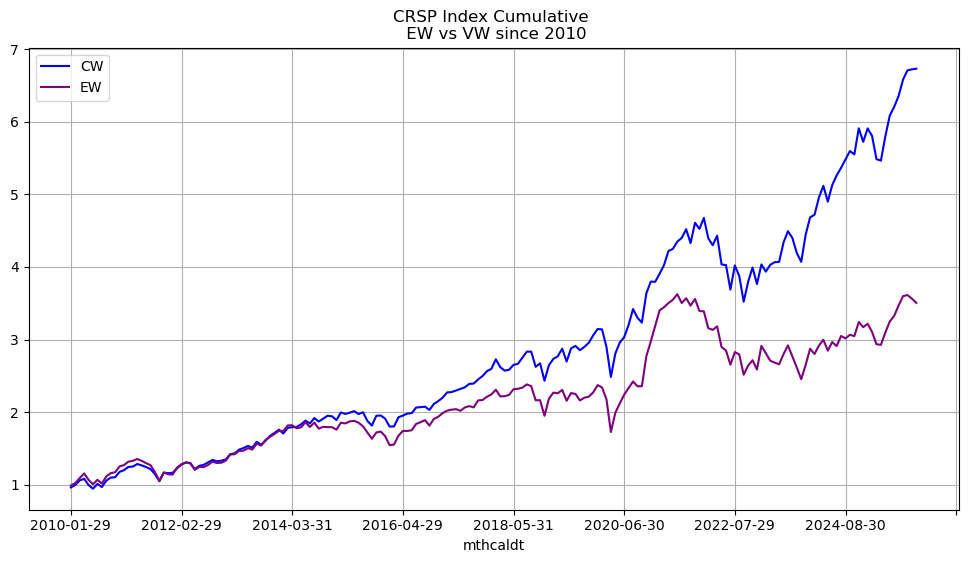

In [36]:
for year in ds_cum.keys():
    ds_cum[year].plot(figsize = (12,6), title = f"CRSP Index Cumulative \n EW vs VW since {year}", 
                  legend = True, grid = True, color=["blue", "purple"])

In [37]:
for start in ["1926", "1960", "1990", "2010"]:
    print("since ",start)
    display(pt.summary_stats(
        data_crsp.loc[start:, ["vwretd", "ewretd"]]
    ))

since  1926


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
vwretd,0.100222,0.183317,0.121516,10.630999,0.067630,0.117993,0.453194,-0.837853
ewretd,0.119511,0.244449,1.472377,18.375729,0.049917,0.143571,0.459405,-0.858733


since  1960


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
vwretd,0.102501,0.152992,-0.513842,4.81464,0.068062,0.096540,0.524159,-0.514774
ewretd,0.114357,0.190160,-0.176069,5.92456,0.079137,0.115748,0.511700,-0.598049


since  1990


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
vwretd,0.103005,0.151332,-0.635602,4.314566,0.069001,0.098183,0.531387,-0.514774
ewretd,0.103871,0.181623,-0.233183,5.321816,0.077456,0.112515,0.474480,-0.558020


since  2010


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
vwretd,0.126546,0.146465,-0.368497,3.849624,0.062081,0.087811,0.68856,-0.246763
ewretd,0.081526,0.165467,-0.227525,5.355539,0.071440,0.097706,0.37907,-0.322928


In [52]:
roll_60_ewd = data_crsp.loc[:,["ewretd"]].rolling(60).apply(lambda x: pt.annualize_rets(x,12))
roll_60_cwd = data_crsp.loc[:,["vwretd"]].rolling(60).apply(lambda x: pt.annualize_rets(x,12))
spread = pd.DataFrame(roll_60_ewd.squeeze()-roll_60_cwd.squeeze()).dropna()
spread.columns = ["EW-CW Spread"]

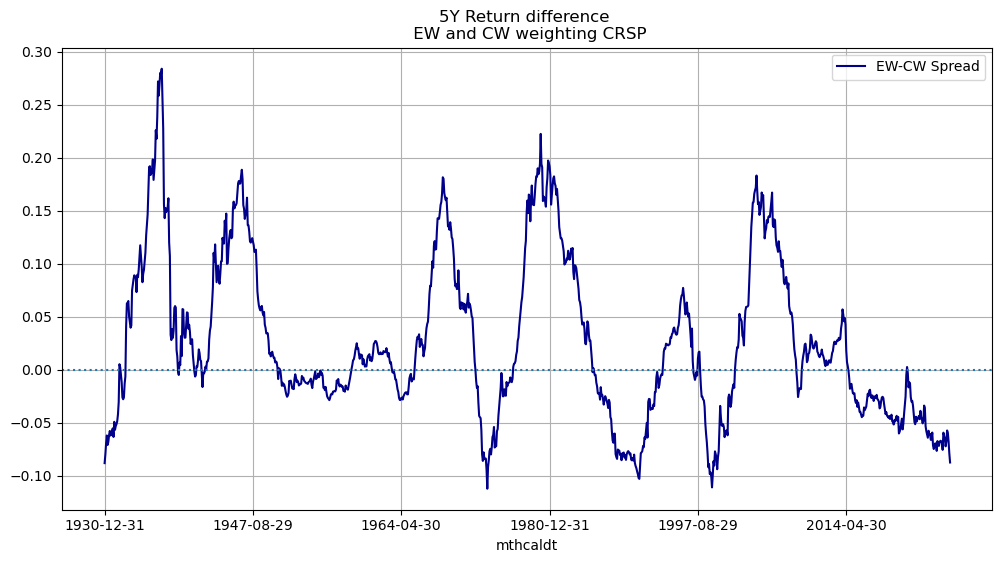

In [239]:
ax = spread.plot(figsize = (12,6), title = f"5Y Return difference \n EW and CW weighting CRSP", 
                  legend = True, grid = True, color="darkblue")
ax.axhline(0, ls = ":")

### Takeaway

The CRSP market indices broadly confirm the earlier pattern: equal weighting tends to deliver higher long-run returns, but with higher volatility and deeper drawdowns. 
The advantage is also highly sample-dependent. Since 1990, EW and VW returns are almost identical, while since 2010 value weighting clearly dominates on both return and Sharpe ratio. This is nicely demonstrated by EW-CW spread evolution over the great period of time - it has gone done and turned negative for more periods than before. 

This suggests that the apparent advantage of equal weighting is not stable through time and should not be judged from cumulative return alone. The next step is therefore to move from aggregate market indices to a fixed stock universe and compare portfolio construction methods directly.

## Now, I would like to verify this pattern consistency on a group of stocks. 
This task will require a more thorough data preparation, I use WRDS - Wharton Research Dataset. I will process this data in a separate Notebook and conduct a more sophisticated analysis.  
This time, we will get more flexibility and compare natural cap-weighting with other alternatives.
```
02_100stock.ipynb